In [1]:
import pathlib 
import numpy as np
import scipy as sp
from matplotlib import pyplot as plt
import pandas as pd

import el_hd_plasticity.two_photon as nmp
from SessionTools import two_photon as st2p

%load_ext autoreload
%autoreload 2

%matplotlib inline

In [2]:
basedir = pathlib.Path('/media/mplitt/SSD_storage/2P_scratch/ER4d_sytjGCaMP7f_R18B05LexA_CsChrimsontdT')
sess_df = pd.read_csv(basedir / 'sessions.csv')
sess_df['fly_id'] = [row['date']+'_'+row['fly'] for _, row in sess_df.iterrows()]



In [3]:
sess_mask = (sess_df['closed_loop']==1) & (sess_df['usable']==1) & (sess_df['remap']==0)
cl_sess_df = sess_df.loc[sess_mask]

In [5]:
def get_ts(pp, coef = .7):
    y_r4d = pp.timeseries['rois_z']
    heading = np.angle(np.exp(1j*(-1*pp.voltage_recording_aligned[' Heading'].to_numpy()-np.pi)))
    bar_vis_mask = (np.abs(heading)<2.14) * (pp.voltage_recording_aligned[' Arena DAC2']<7)
   
    # y_r4d-=1
    
    
    y_r4d_sm = sp.ndimage.gaussian_filter1d(sp.ndimage.gaussian_filter1d(y_r4d, .7, axis=1,mode='wrap'),2,axis=-1)
    

    y_r4d_norm = y_r4d_sm-y_r4d_sm.mean(axis=1,keepdims=True)

    
    n_rois = y_r4d.shape[1]
    x_f,y_f = st2p.utilities.pol2cart(y_r4d_sm[1,:,:] ,np.linspace(-np.pi,np.pi,num=n_rois)[:,np.newaxis])
    rho_r4d, phi_r4d = st2p.utilities.cart2pol(x_f.mean(axis=0), y_f.mean(axis=0))

    

    _,offset_r4d = st2p.utilities.cart2pol(*st2p.utilities.pol2cart(np.ones(heading.shape),phi_r4d-heading))
    
    
    return {'heading': heading,
            'bar_vis_mask': bar_vis_mask,
            'y_r4d': y_r4d,
    
            'y_r4d_sm': y_r4d_sm,
            'y_r4d_norm': y_r4d_norm,
    
            'rho_r4d': rho_r4d,
            'phi_r4d': phi_r4d,
            'offset_r4d': offset_r4d,
    }

def align_to_heading(ts):
    heading_bins = np.linspace(-np.pi, np.pi, num=17)
    heading_dig = np.digitize(ts['heading'], heading_bins)-1

    y_h_aligned = np.zeros_like(ts['y_r4d_norm'])
    for ind in range(ts['heading'].shape[0]):
        y_h_aligned[-1,:,ind] = np.roll(ts['y_r4d_norm'][-1,:,ind], -heading_dig[ind])
        
    # y_h_aligned_z = np.zeros((2,16,16))
    # for b in range(16):
    #     mask = heading_dig==b
    #     y_h_aligned_z[:,:,b] = y_h_aligned[:,:,mask].mean(axis=-1)
    

    
    
    return heading_bins, y_h_aligned #, y_h_aligned_z

   

In [6]:
fly_ids = sess_df['fly_id'].unique()

In [7]:
fly_ids

<ArrowStringArray>
['30_08_2024_fly1', '30_08_2024_fly2', '03_09_2024_fly1', '03_09_2024_fly2',
 '03_09_2024_fly3', '03_09_2024_fly4', '04_09_2024_fly1', '04_09_2024_fly2',
 '04_09_2024_fly3', '05_09_2024_fly1', '05_09_2024_fly2', '05_09_2024_fly3',
 '05_09_2024_fly4', '09_09_2024_fly1', '09_09_2024_fly2', '09_09_2024_fly3',
 '09_09_2024_fly4', '09_09_2024_fly5', '09_09_2024_fly6']
Length: 19, dtype: str

In [9]:
fly_df = []
for _, row in cl_sess_df.iterrows():
    outdir = pathlib.PurePath( basedir / row['date'] / row['fly'] / row['sess'] / 'preprocess.pkl')
    pp = st2p.preprocessing.EBImagingSession.from_file(outdir)
    print(row['fly_id'], row['offset'])
    offset = row['offset']
    mask = (np.abs(pp.voltage_recording_aligned[' Heading'])<2.5)&(pp.voltage_recording_aligned[' Arena DAC2']<8)

    
    ts = get_ts(pp, coef=.0)
    _, y_h_aligned = align_to_heading(ts)
    print(y_h_aligned.shape)

    y_h_aligned_mean = y_h_aligned[-1,:, :][:, mask].mean(axis=-1)

    fly_df.append({
        'fly_id': row['fly_id'],
        'offset': offset,
        'y_h_aligned_mean': y_h_aligned_mean})

        
# fly_df = pd.DataFrame(fly_df)

30_08_2024_fly1 -1
(2, 16, 1657)
30_08_2024_fly1 180
(2, 16, 1657)
30_08_2024_fly2 -1
(2, 16, 1934)
30_08_2024_fly2 0
(2, 16, 1934)
04_09_2024_fly3 0
(2, 16, 1393)
04_09_2024_fly3 180
(2, 16, 1393)
05_09_2024_fly1 -1
(2, 16, 1404)
05_09_2024_fly1 0
(2, 16, 1404)
05_09_2024_fly1 180
(2, 16, 1404)
05_09_2024_fly2 -1
(2, 16, 1487)
05_09_2024_fly2 180
(2, 16, 1487)
05_09_2024_fly2 0
(2, 16, 1487)
05_09_2024_fly3 -1
(2, 16, 1340)
05_09_2024_fly3 0
(2, 16, 1340)
05_09_2024_fly3 180
(2, 16, 1340)
05_09_2024_fly4 -1
(2, 16, 1487)
05_09_2024_fly4 180
(2, 16, 1487)
05_09_2024_fly4 0
(2, 16, 1487)
09_09_2024_fly1 -1
(2, 16, 1438)
09_09_2024_fly1 180
(2, 16, 1438)
09_09_2024_fly1 0
(2, 16, 1438)
09_09_2024_fly2 -1
(2, 16, 1360)
09_09_2024_fly2 0
(2, 16, 1360)
09_09_2024_fly2 180
(2, 16, 1360)
09_09_2024_fly3 -1
(2, 16, 1404)
09_09_2024_fly3 180
(2, 16, 1404)
09_09_2024_fly3 0
(2, 16, 1404)
09_09_2024_fly4 -1
(2, 16, 1450)
09_09_2024_fly4 0
(2, 16, 1450)
09_09_2024_fly4 180
(2, 16, 1450)


In [15]:
fly_df = pd.DataFrame(fly_df)
fly_df.head()

,fly_id,offset,y_h_aligned_mean
0,30_08_2024_fly1,-1,"[-0.0018059476288860867, -0.002097870630309914..."
1,30_08_2024_fly1,180,"[-0.03271434967089279, -0.01295644968736682, 0..."
2,30_08_2024_fly2,-1,"[0.10144822662885755, 0.0555673883350257, 0.03..."
3,30_08_2024_fly2,0,"[0.015619546918887228, 0.050269726279997436, 0..."
4,04_09_2024_fly3,0,"[-0.0010129786716059819, 0.03904225422591391, ..."


30_08_2024_fly1 (0,)
30_08_2024_fly2 (1,)
04_09_2024_fly3 (1,)
05_09_2024_fly1 (1,)
05_09_2024_fly2 (1,)
05_09_2024_fly3 (1,)
05_09_2024_fly4 (1,)
09_09_2024_fly1 (1,)
09_09_2024_fly2 (1,)
09_09_2024_fly3 (1,)
09_09_2024_fly4 (1,)


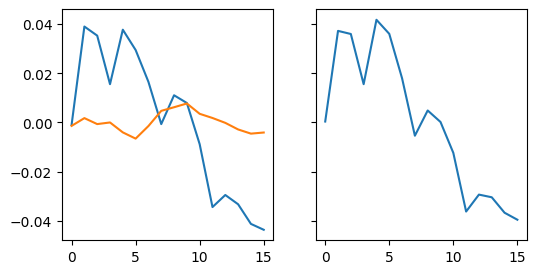

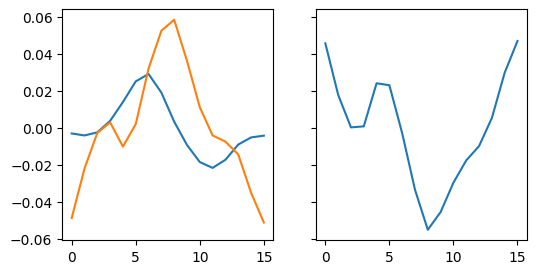

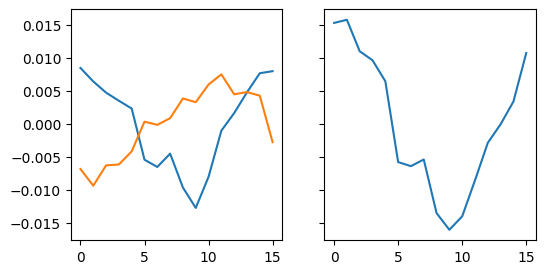

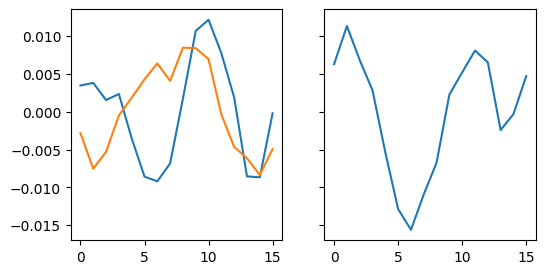

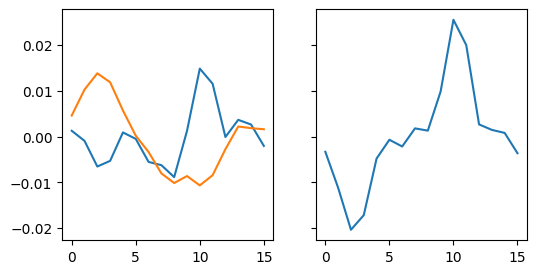

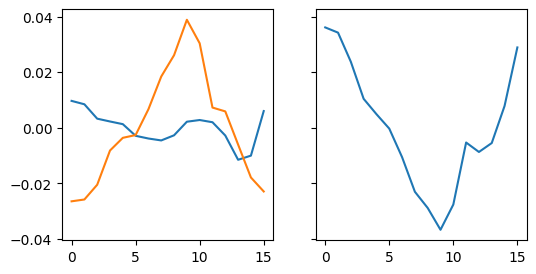

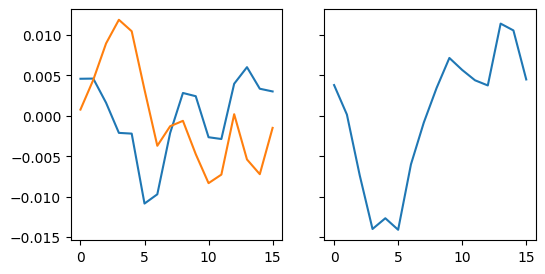

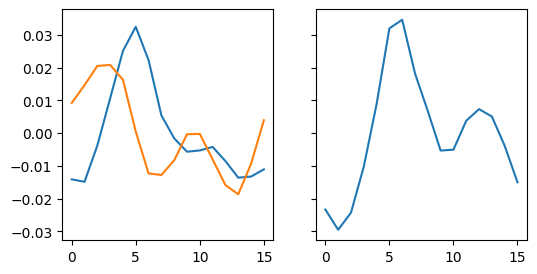

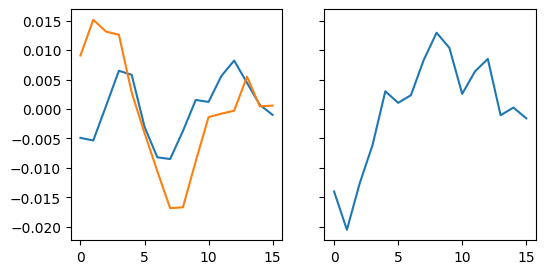

In [44]:
diff = []
for fly in fly_df['fly_id'].unique():
    df = fly_df.loc[fly_df['fly_id']==fly]
    # print(df)
    off0 = df.loc[df['offset']==0, 'y_h_aligned_mean']
    off180 = df.loc[df['offset']==180, 'y_h_aligned_mean']
    print(fly, off0.shape)
    if off0.shape[0]==0 or off180.shape[0]==0:
        continue
    else:
        off0 = off0.values[0]
        off180 = off180.values[0]
    # print(fly, off0, off180)

    fig, ax = plt.subplots(1,2, figsize=(6,3), sharey=True)
    ax[0].plot(off0)
    ax[0].plot(off180)
    ax[1].plot(off0-off180)

    diff.append(off0-off180)
diff = np.array(diff)

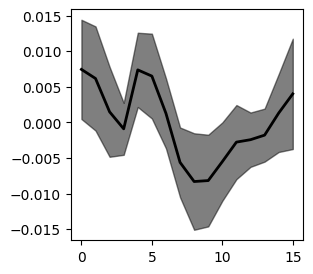

In [46]:
fig, ax = plt.subplots(1,1, figsize=(3,3))



mu, sem = diff.mean(axis=0), diff.std(axis=0)/np.sqrt(diff.shape[0])
ax.fill_between(np.arange(diff.shape[1]), mu-sem, mu+sem, alpha=.5, color='k')
ax.plot(mu, color='k', lw=2)

[ 0.00037907  0.03727282  0.03600859  0.015584    0.04179324  0.0360645
  0.01797101 -0.00539124  0.00487547  0.00019797 -0.01237116 -0.03625382
 -0.02936014 -0.03044737 -0.03673826 -0.03958466]
[ 0.04569022  0.01787828  0.00027373  0.00081336  0.02410341  0.02304565
 -0.0029293  -0.03344013 -0.05506368 -0.04546334 -0.02960133 -0.01756223
 -0.00983039  0.00532954  0.02981019  0.04694601]
[ 1.53101661e-02  1.57896264e-02  1.10171247e-02  9.65649733e-03
  6.48229134e-03 -5.76240523e-03 -6.37670734e-03 -5.37046895e-03
 -1.34955353e-02 -1.60175538e-02 -1.39784925e-02 -8.53003629e-03
 -2.84555023e-03 -3.14556971e-05  3.40260371e-03  1.07498958e-02]
[ 0.00630088  0.01134035  0.00684763  0.00283632 -0.00536131 -0.01285617
 -0.01559651 -0.01092288 -0.00672425  0.00227955  0.00521009  0.00810167
  0.00654385 -0.00241158 -0.00030582  0.00471818]
[-0.00332378 -0.0111888  -0.02034689 -0.01715371 -0.00479203 -0.0006965
 -0.00216639  0.00178929  0.00129441  0.00984585  0.02549412  0.01996794
  0.002

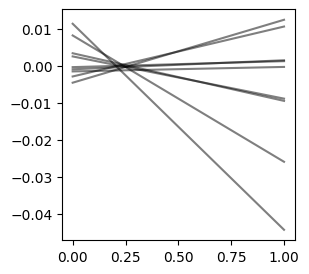

In [55]:
fig, ax = plt.subplots(1,1, figsize=(3,3))
for row in diff:
    print(row)
    ax.plot([row[[0,1,2,3,4,5,10,11,12,13,14,15]].mean(), row[[7,8]].mean()], color='k', alpha=.5)

In [56]:
t, p = sp.stats.wilcoxon(diff[:, [7,8]].mean(axis=-1), 0)
print(f't={t:.3f}, p={p:.3e}')

t=18.000, p=6.523e-01
